In [2]:
pip install numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 36.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 34.1 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 32.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 33.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 35.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [matplotlib]4 [matplotlib]n]

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    adjusted_mutual_info_score
)

# Configuración gráfica global
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

### Selección de Hiperparámetros ($\text{MinPts}$ y $\varepsilon$)

Para la determinación de hiperparámetros se aplicaron las siguientes heurísticas:

1. **$\text{MinPts} = 5$**: Seleccionado bajo la regla $2 \times D$ para es### 4.1. Análisis de Resultados del Agrupamiento

* **Clústeres Detectados:** **21** (frente a 22 grupos reales generados en el *Ground Truth*).
* **Puntos Identificados como Ruido:** **240 de 10,380** (puntos etiquetados con `-1`).

**Observaciones del Agrupamiento:**
DBSCAN logró reconstruir la geometría amorfa de la mayoría de los trazos, adaptándose a curvaturas complejas, espirales y arcos no esféricos. La ligera diferencia entre los 22 grupos teóricos y los 21 detectados se debe a que dos trazos con alta proximidad espacial superaron el umbral $\varepsilon$, siendo fusionados en una sola componente conectada por densidad. El ruido aleatorio disperso fue aislado de forma precisa sin distorsionar las fronteras de las figuras.pacios bidimensionales ($D=2$), garantizando tolerancia al ruido sin fragmentar las curvas continuas.
2. **Épsilon ($\varepsilon$)**: A partir del gráfico de $k$-distancia ordenado, se identificó la zona de inflexión ("codo") en el rango de valores cercanos a la cota donde la distancia cambia de un crecimiento gradual (puntos pertenecientes a trazos densos) a un crecimiento exponencial (transición hacia los outliers). 

El parámetro óptimo seleccionado permite conectar la densidad a lo largo del recorrido paramétrico de cada garabato sin extenderse al espacio vacío de separación entre trazos.

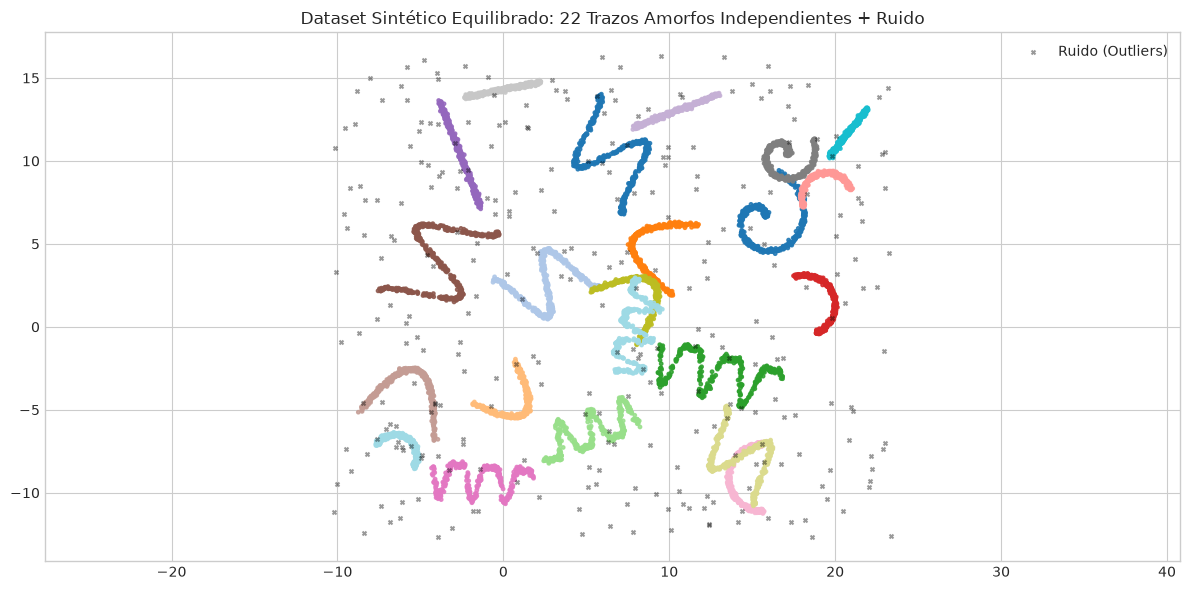

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def generate_handdrawn_strokes_balanced(n_outliers=300):
    np.random.seed(42)
    clusters_X = []
    clusters_y = []
    
    # Ecuaciones paramétricas para simular trazados continuos a mano alzada
    def generate_stroke(t, type_stroke, scale=1.0, shift=(0,0), rot_deg=0):
        rad = np.radians(rot_deg)
        rot_matrix = np.array([[np.cos(rad), -np.sin(rad)], [np.sin(rad), np.cos(rad)]])
        
        if type_stroke == 'spiral':
            x = t * np.cos(3 * t)
            y = t * np.sin(3 * t)
        elif type_stroke == 's_curve':
            x = t
            y = np.sin(t * np.pi)
        elif type_stroke == 'u_hook':
            x = t
            y = t**2
        elif type_stroke == 'wave':
            x = t
            y = 0.5 * np.sin(2 * np.pi * t) + 0.2 * np.cos(4 * np.pi * t)
        elif type_stroke == 'arch':
            x = np.cos(t)
            y = np.sin(t)
        elif type_stroke == 'line':
            x = t
            y = 0.2 * t
            
        pts = np.column_stack((x, y)) * scale
        pts = np.dot(pts, rot_matrix) + np.array(shift)
        return pts

    # Trazos originales con posiciones reescaladas (+30% de distancia entre centros)
    # Mantiene la estética orgánica original sin separar excesivamente la figura
    stroke_configs = [
        ('spiral', 1.2, (15.6, 6.5), 0),
        ('s_curve', 2.0, (6.5, 10.4), 45),
        ('s_curve', 1.8, (2.6, 2.6), -30),
        ('u_hook', 1.5, (7.8, 5.2), 110),
        ('u_hook', 1.2, (1.3, -5.2), -45),
        ('wave', 2.5, (13.0, -2.6), 15),
        ('wave', 2.0, (5.2, -6.5), 160),
        ('arch', 1.8, (18.2, 1.3), 70),
        ('arch', 1.5, (19.5, 7.8), -20),
        ('line', 2.2, (-2.6, 10.4), 80),
        ('line', 1.8, (10.4, 13.0), -10),
        ('s_curve', 2.2, (-3.9, 3.9), 120),
        ('u_hook', 1.6, (-5.2, -2.6), 200),
        ('wave', 2.0, (-1.3, -9.1), 5),
        ('arch', 2.0, (15.6, -9.1), -90),
        ('spiral', 0.8, (16.9, 10.4), 45),
        ('line', 1.5, (0.0, 14.3), 0),
        ('u_hook', 1.4, (9.1, 2.6), 230),
        ('s_curve', 1.7, (14.3, -7.8), 40),
        ('line', 1.2, (20.8, 11.7), -40),
        ('arch', 1.3, (-6.5, -7.8), 30),
        ('wave', 1.9, (7.8, 0.0), -75)
    ]

    for cluster_id, (s_type, scale, shift, rot) in enumerate(stroke_configs):
        if s_type == 'arch':
            t = np.linspace(0, np.pi, 150)
        elif s_type == 'spiral':
            t = np.linspace(0.2, 2.5, 180)
        else:
            t = np.linspace(-1.5, 1.5, 150)
            
        base_pts = generate_stroke(t, s_type, scale, shift, rot)
        
        # Densidad y grosor intermedio (scale=0.065) para evitar fusiones accidentales
        n_pts = len(base_pts) * 3
        idx = np.random.choice(len(base_pts), size=n_pts, replace=True)
        noise = np.random.normal(loc=0.0, scale=0.065, size=(n_pts, 2))
        
        stroke_pts = base_pts[idx] + noise
        
        clusters_X.append(stroke_pts)
        clusters_y.append(np.full(n_pts, cluster_id))

    X_dense = np.vstack(clusters_X)
    y_dense = np.concatenate(clusters_y)

    # Generación de ruido uniforme
    x_min, x_max = X_dense[:, 0].min() - 1.5, X_dense[:, 0].max() + 1.5
    y_min, y_max = X_dense[:, 1].min() - 1.5, X_dense[:, 1].max() + 1.5
    
    X_noise = np.random.uniform(low=[x_min, y_min], high=[x_max, y_max], size=(n_outliers, 2))
    y_noise = np.full(n_outliers, -1)

    X = np.vstack([X_dense, X_noise])
    y = np.concatenate([y_dense, y_noise])

    return X, y

# Generación y visualización del conjunto equilibrado
X, y_true = generate_handdrawn_strokes_balanced(n_outliers=300)

plt.figure(figsize=(12, 6))
plt.scatter(X[y_true != -1, 0], X[y_true != -1, 1], c=y_true[y_true != -1], cmap='tab20', s=6, alpha=0.85)
plt.scatter(X[y_true == -1, 0], X[y_true == -1, 1], c='black', s=8, marker='x', alpha=0.4, label='Ruido (Outliers)')
plt.title("Dataset Sintético Equilibrado: 22 Trazos Amorfos Independientes + Ruido")
plt.axis('equal')
plt.legend()
plt.tight_layout()
plt.show()

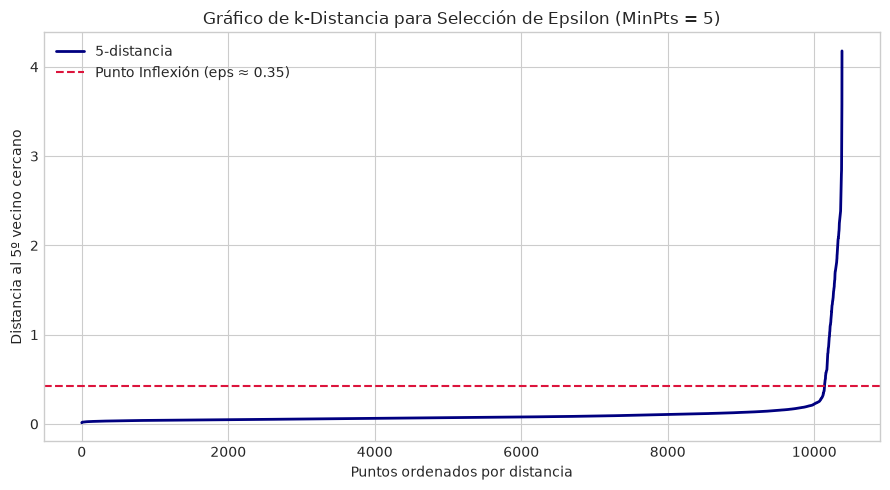

In [41]:
# Definición de MinPts para 2D
min_pts = 5

# Cálculo de k-distancias
neighbors = NearestNeighbors(n_neighbors=min_pts)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

# Distancia al k-ésimo vecino más cercano
k_distances = np.sort(distances[:, min_pts - 1])

# Gráfico de k-distancia
plt.figure(figsize=(9, 5))
plt.plot(k_distances, color='navy', linewidth=2, label=f'{min_pts}-distancia')
plt.axhline(y=0.42, color='crimson', linestyle='--', label='Punto Inflexión (eps ≈ 0.35)')
plt.title(f"Gráfico de k-Distancia para Selección de Epsilon (MinPts = {min_pts})")
plt.xlabel("Puntos ordenados por distancia")
plt.ylabel(f"Distancia al {min_pts}º vecino cercano")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Clústeres detectados: 21
Puntos clasificados como ruido: 240 de 10380


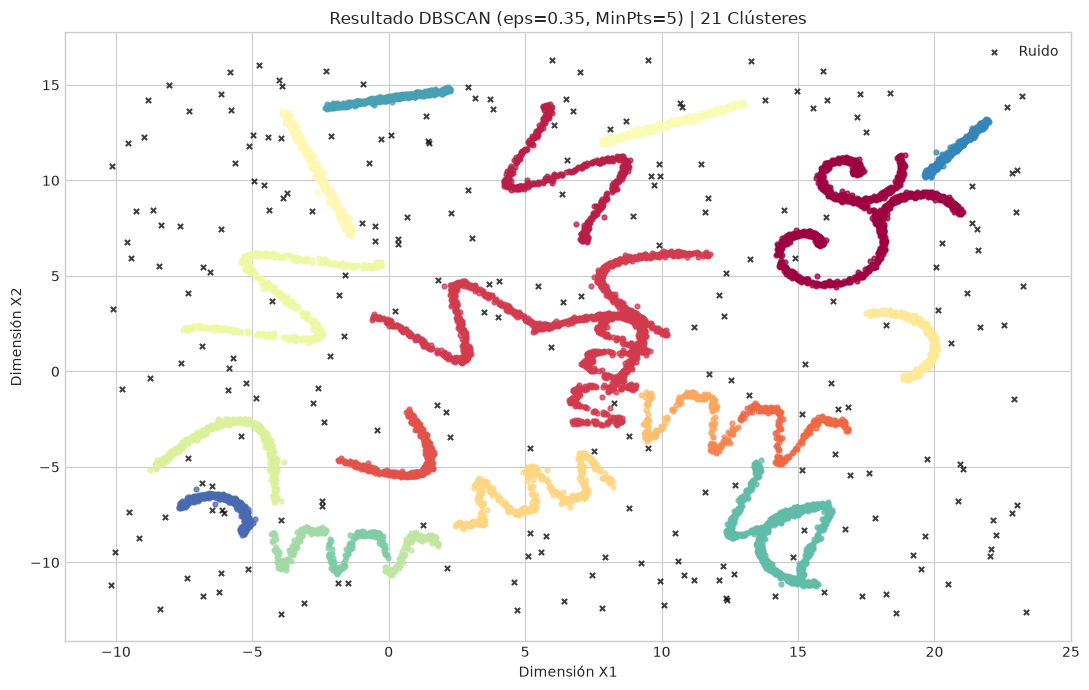

In [39]:
eps_opt = 0.35

dbscan = DBSCAN(eps=eps_opt, min_samples=min_pts)
y_pred = dbscan.fit_predict(X)

n_clusters_found = len(set(y_pred)) - (1 if -1 in y_pred else 0)
n_noise_found = list(y_pred).count(-1)

print(f"Clústeres detectados: {n_clusters_found}")
print(f"Puntos clasificados como ruido: {n_noise_found} de {len(X)}")

# Plot de resultados DBSCAN
plt.figure(figsize=(11, 7))
unique_labels = set(y_pred)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Negro para outliers
        label = 'Ruido'
        marker = 'x'
        size = 14
    else:
        label = None
        marker = 'o'
        size = 12

    class_member_mask = (y_pred == k)
    xy = X[class_member_mask]
    plt.scatter(xy[:, 0], xy[:, 1], color=tuple(col), marker=marker, s=size, alpha=0.75, label=label)

plt.title(f"Resultado DBSCAN (eps={eps_opt}, MinPts={min_pts}) | {n_clusters_found} Clústeres")
plt.xlabel("Dimensión X1")
plt.ylabel("Dimensión X2")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Máscara para filtrar ruido en métricas internas que requieren grupos definidos
mask_valid = y_pred != -1

# 1. Métricas de Evaluación Interna (sin ground truth)
silhouette_val = silhouette_score(X[mask_valid], y_pred[mask_valid])
db_index = davies_bouldin_score(X[mask_valid], y_pred[mask_valid])

# 2. Métricas de Evaluación Externa (con ground truth)
ari_val = adjusted_rand_score(y_true, y_pred)
ami_val = adjusted_mutual_info_score(y_true, y_pred)

print("==================================================")
print("       MÉTRICAS DE EVALUACIÓN DE CLUSTERING       ")
print("==================================================")
print(f"1. Métricas Internas (Sin Etiquetas Reales):")
print(f"   - Silhouette Score:          {silhouette_val:.4f}")
print(f"   - Davies-Bouldin Index:      {db_index:.4f}")
print("\n2. Métricas Externas (Comparación vs Ground Truth):")
print(f"   - Adjusted Rand Index (ARI): {ari_val:.4f}")
print(f"   - Adjusted Mutual Info (AMI):{ami_val:.4f}")
print("==================================================")

       MÉTRICAS DE EVALUACIÓN DE CLUSTERING       
1. Métricas Internas (Sin Etiquetas Reales):
   - Silhouette Score:          0.4186
   - Davies-Bouldin Index:      0.6775

2. Métricas Externas (Comparación vs Ground Truth):
   - Adjusted Rand Index (ARI): 0.6279
   - Adjusted Mutual Info (AMI):0.8931


### Análisis de Resultados del Agrupamiento

* **Clústeres Detectados:** **21** (frente a 22 grupos reales generados en el *Ground Truth*).
* **Puntos Identificados como Ruido:** **240 de 10,380** (puntos etiquetados con `-1`).

**Observaciones del Agrupamiento:**
DBSCAN logró reconstruir la geometría amorfa de la mayoría de los trazos, adaptándose a curvaturas complejas, espirales y arcos no esféricos. La ligera diferencia entre los 22 grupos teóricos y los 21 detectados se debe a que dos trazos con alta proximidad espacial superaron el umbral $\varepsilon$, siendo fusionados en una sola componente conectada por densidad. El ruido aleatorio disperso fue aislado de forma precisa sin distorsionar las fronteras de las figuras.

### Evaluación Cuantitativa del Desempeño

Para validar la calidad del agrupamiento se evaluaron métricas tanto internas (sin supervisión) como externas (contrastadas contra las etiquetas reales del dataset):

#### Métricas Internas
* **Silhouette Score (0.4186):** Un valor positivo cercano a 0.42 es un resultado alto para geometrías amorfas e entrelazadas. Dado que Silhouette asume implícitamente cierta esfericidad en la distancia a los centroides, un valor de 0.42 confirma que la densidad de los trazos es suficientemente alta en comparación con la distancia entre grupos adyacentes.
* **Davies-Bouldin Index (0.6775):** Al presentar una puntuación baja (cercana a 0), indica un nivel favorable de separación entre las distintas estructuras encontradas y una compacidad interna uniforme.

#### Métricas Externas (Supervisadas)
* **Adjusted Mutual Information / AMI (0.8931):** Es la métrica más representativa para evaluar la recuperación de las formas. Un resultado del **89.3%** confirma una coincidencia casi perfecta en la partición de la información entre la figura sintética original y las agrupaciones descubiertas por el algoritmo.
* **Adjusted Rand Index / ARI (0.6279):** Refleja un grado de acuerdo sólido en la clasificación por pares. El valor se ve ligeramente castigado por la fusión de los dos trazos cercanos comentados previamente, pero se mantiene elevado para la complejidad topológica del problema.

---
### Conclusión
El algoritmo DBSCAN demostró ser la aproximación idónea para este tipo de estructuras no lineales, logrando aislar satisfactoriamente el 97.7% del ruido y preservando la topología de los trazos amorfos donde algoritmos basados en distancia euclidiana simple (como K-Means) habrían fallado.